In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

In [4]:
df = pd.read_csv(r"D:\tasks\Adult Census Income(Target column income).csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [6]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:\n", df.duplicated().sum())
print('Target Distribution:\n', df['income'].value_counts())

Missing Values:
 age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64
Duplicate Rows:
 24
Target Distribution:
 income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [7]:
for col in df.select_dtypes(include='string').columns:
    df[col] = df[col].str.strip()

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})
df_clean = df.drop(columns=['education'])

print("Cleaned Shape:", df_clean.shape)

Cleaned Shape: (32537, 14)


In [9]:
df_clean.head()

,age,workclass,fnlwgt,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_5164\1207788506.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df_clean, palette='viridis', ax=axes[0, 0])
C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_5164\1207788506.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='education.num', data=df_clean, palette='viridis', ax=axes[1, 0])
C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_5164\1207788506.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='hours.per.week', data=df_clean, palette='viridis'

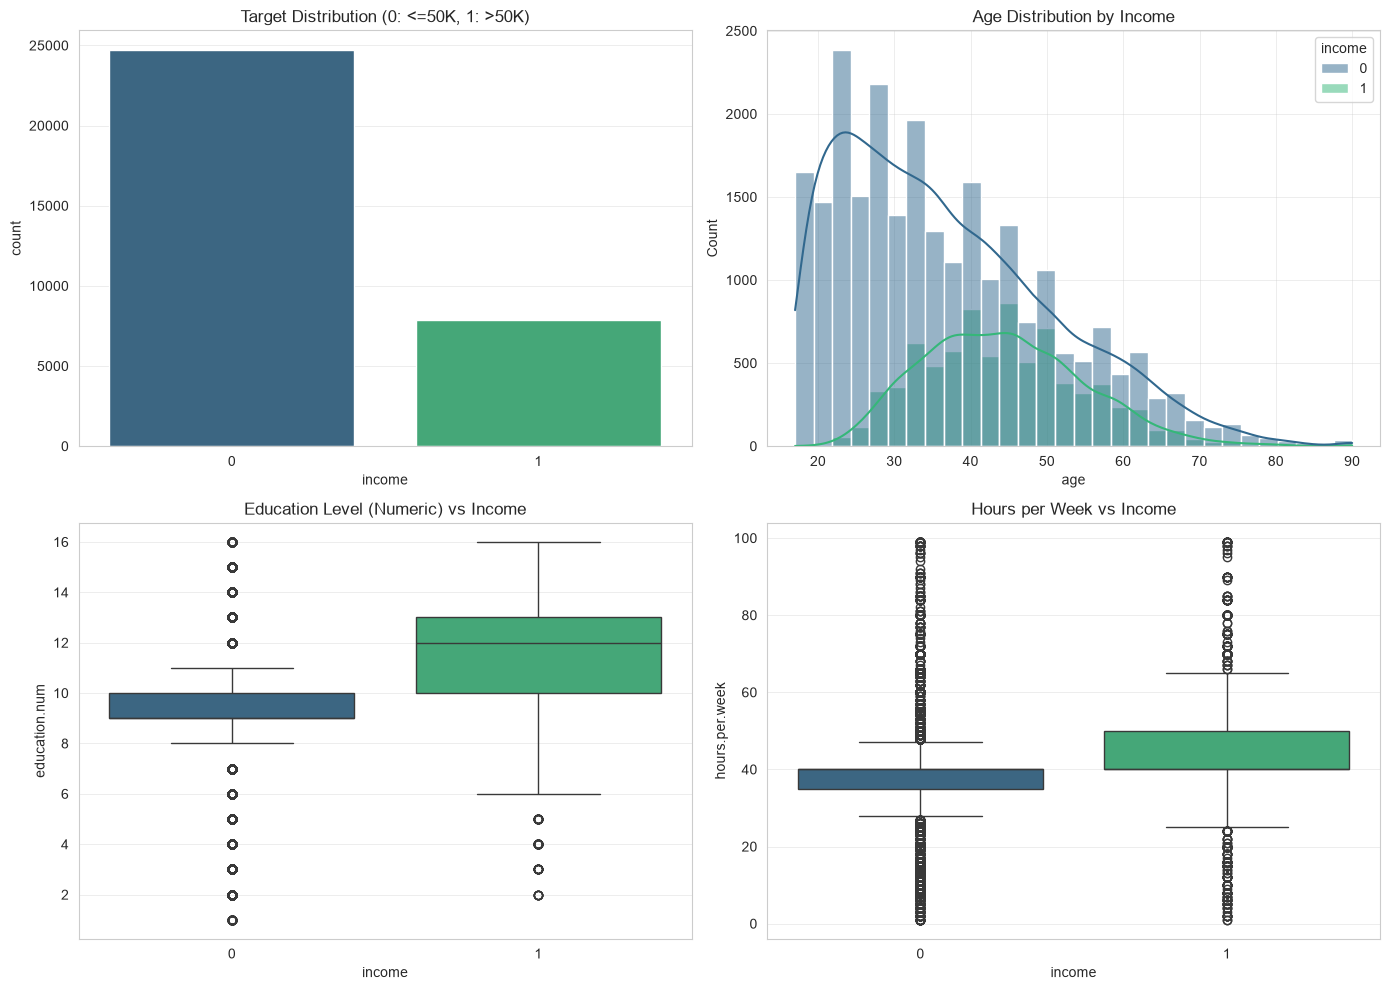

In [10]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x='income', data=df_clean, palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title('Target Distribution (0: <=50K, 1: >50K)')
sns.histplot(data=df_clean, x='age', hue='income', kde=True, bins=30, palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution by Income')

sns.boxplot(x='income', y='education.num', data=df_clean, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_title('Education Level (Numeric) vs Income')

sns.boxplot(x='income', y='hours.per.week', data=df_clean, palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('Hours per Week vs Income')

plt.tight_layout()
plt.show()

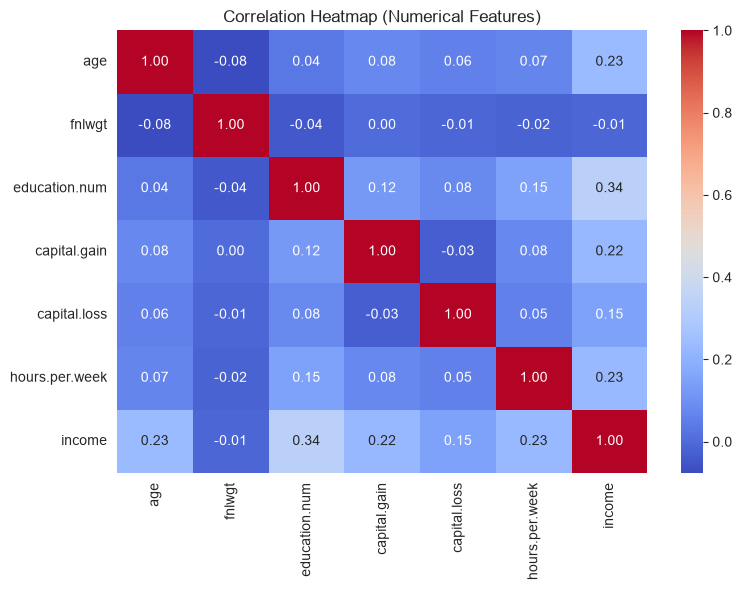

In [11]:
plt.figure(figsize=(8, 6))
num_cols_all = df_clean.select_dtypes(include=[np.number]).columns
sns.heatmap(df_clean[num_cols_all].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (Numerical Features)')
plt.tight_layout()
plt.show()

In [12]:
X = df_clean.drop(columns=['income'])
y = df_clean['income']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_5164\65784043.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [14]:
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [15]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

In [16]:
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_proc.shape)
print("Processed X_test shape:", X_test_proc.shape)

Processed X_train shape: (26029, 89)
Processed X_test shape: (6508, 89)


In [17]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'KNN (k=7)': KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Gaussian Naive Bayes': GaussianNB(),
    'Linear SVM': LinearSVC(max_iter=2000, random_state=42),
    'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=50, random_state=42)
}

In [20]:
results = []
trained_models = {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_proc, y_train)
    train_time = time.time() - t0
    trained_models[name] = model

    y_pred = model.predict(X_test_proc)

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test_proc)[:, 1]
    else:
        y_score = model.decision_function(X_test_proc)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Train Time (s)': round(train_time, 2)
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df

D:\charmPrj\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,HistGradientBoosting,0.877074,0.784024,0.676020,0.726027,0.930969,2.22
1,Gradient Boosting,0.871696,0.795803,0.628827,0.702529,0.927099,14.86
2,MLP Neural Network,0.854487,0.702280,0.687500,0.694811,0.911266,29.81
3,Random Forest,0.861401,0.748137,0.640306,0.690034,0.909883,1.31
4,Decision Tree,0.864167,0.784526,0.601403,0.680866,0.904522,0.46
5,Logistic Regression,0.856484,0.740516,0.622449,0.676369,0.909495,1.07
6,Linear SVM,0.856638,0.748241,0.610332,0.672287,0.909400,0.36
7,KNN (k=7),0.842348,0.690309,0.626913,0.657086,0.876137,0.01
8,Extra Trees,0.842655,0.696816,0.614158,0.652881,0.890931,1.79
9,AdaBoost,0.857099,0.790000,0.554209,0.651424,0.907846,5.16


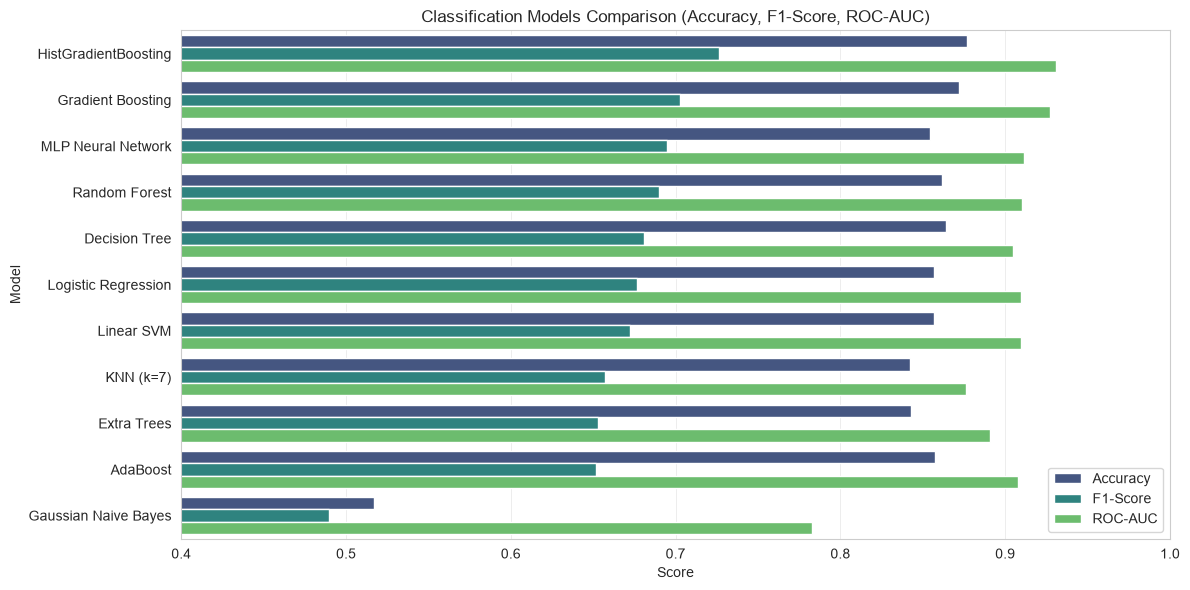

In [21]:
plt.figure(figsize=(12, 6))
melted = results_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score'
)
sns.barplot(data=melted, x='Score', y='Model', hue='Metric', palette='viridis')
plt.title('Classification Models Comparison (Accuracy, F1-Score, ROC-AUC)')
plt.xlim(0.4, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()